# SMT × MemUP, Stack без шума — версия 02

**Статус.** Здесь подготовлен код следующего эксперимента и выполнены технические проверки, аудит данных и аудит отбора целей. **Обучения SMT/DMT в этом ноутбуке не запускались**: ячейки фаз 1–4 по умолчанию выключены. Все числа из версии 01 вынесены в архивный раздел в конце и не являются результатами этого кода.

Код эксперимента лежит в `smt_memup_stack.py` (один файл, импорт ничего не обучает). Ноутбук его импортирует, проверяет и вызывает фазы. Хэш файла входит в идентификатор запуска: после любой правки кода создаётся новый каталог `runs/stack02_<key>`, старые checkpoints не подхватываются молча.

| Фаза | Что делает | Обучение | Test |
|---|---|---|---|
| 0. audit | данные, два detector, аудит отбора | только маленькие GRU | нет |
| 1. baseline | SMT→DMT baseline на tuning-seed, gate, probe H2 | 1 fit | нет |
| 2. tune | одинаковая alpha-сетка и бюджет для каждого небазового варианта | 3 × 3 fits | нет |
| 3. final | 3 seeds × 4 варианта, alpha зафиксированы | 12 fits | нет |
| 4. report | создаёт test один раз, парные сравнения | нет | да |

## 0. Гипотеза и границы

$$L = L_{\mathrm{SMT}} + \alpha\, L_{\mathrm{selected}},\qquad s_k = -\log q_\eta(y_k \mid \text{локальный контекст}).$$

* **H1.** При одинаковых архитектуре, данных, бюджете и подборе alpha дополнительная CE на K будущих целях с наибольшим score улучшает ответы, требующие давней памяти (pop с delay ≥ 8), сильнее, чем random-K и равномерное усиление decoder loss.
* **H2.** Энкодер (teacher) хранит нужную информацию, а рекуррентный updater теряет её при последовательных обновлениях. Проверяется отдельно: teacher vs RNN до/после DMT и probe «RNN стартует из памяти teacher и делает L шагов».
* $L_{\mathrm{SMT}}$ — авторская сумма трёх слагаемых с авторскими коэффициентами и **авторской нормировкой decoder CE (среднее по всем парам anchor–цель)**. Score замороженный, отбор без градиента, metadata при отборе не используется (кроме явно помеченного oracle-контроля).
* Согласовано с научником: добавочное MemUP-inspired слагаемое к исходному SMT loss, старт без шума (Stack/MQAR), отдельная проверка переноса в RNN. **Окно r=8, K, размеры, шаги, seeds, пороги gate и первичная метрика — наши настройки**, научником не фиксировались.
* Это адаптация принципа MemUP к SMT, а не воспроизведение MemUP. Noisy TV, MQAR, MNIST, utility/binding-aware score здесь не трогаем.

**Почему MemUP может помочь на Stack и где это не гарантировано.** У pop с большой давностью источник лежит далеко; при равномерной decoder CE таких пар мало (≈15% pop имеют delay ≥ 8), и сигнал для «долгой» части памяти слабый. MemUP предлагает перевзвесить именно цели, которые плохо предсказуемы без долговременной памяти. Ограничение: в SMT decoder для anchor t видит **все** входы x_{t+1..k}. Если элемент был положен в стек после t, ответ восстановим из x_fut без m_t — такой target неожиданен для локального окна, но не учит память anchor. Раздел 4 измеряет, какая доля выбранных целей действительно требует m_t.

## 1. Среда

Отдельное окружение (не из проекта dub): `/mem/envs/smt-memup`, Python 3.12, `torch 2.9.1+cu128`, `x-transformers 2.18.5`. Ядро Jupyter: **Python (smt-memup)**.

```bash
uv venv --python 3.12 /mem/envs/smt-memup
uv pip install --python /mem/envs/smt-memup/bin/python torch==2.9.1 torchvision==0.24.1 --index-url https://download.pytorch.org/whl/cu128
uv pip install --python /mem/envs/smt-memup/bin/python numpy==2.1.0 pandas==2.3.3 matplotlib==3.10.8 einops==0.8.1 x-transformers==2.18.5 tqdm==4.67.1 ipykernel nbformat nbclient
```

Сервер общий: процесс ограничивает CPU-потоки и долю памяти GPU (`setup_runtime`). Пик SMT при batch 32 и всех anchors ≈ 7,7 ГБ, поэтому лимит 0,35 от 32 ГБ оставляет запас соседям.

In [1]:
import sys, json, subprocess, importlib
from pathlib import Path
from dataclasses import asdict, replace
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path("/mem/work")                 # здесь лежат smt_memup_stack.py и upstream/
sys.path.insert(0, str(ROOT))
import smt_memup_stack as S
importlib.reload(S)

DEVICE = S.setup_runtime(threads=4, gpu_memory_fraction=0.35)
src = S.sources(ROOT)
CFG = S.Config()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__, "| code sha256", S.code_sha256()[:16], "| upstream", src.revisions)

# Палитра: фиксированный порядок категориальных цветов, тонкие линии, приглушённая сетка.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
VARIANT_COLOR = dict(baseline="#52514e", uniform=SERIES[0], random_k=SERIES[1], surprise_k=SERIES[2],
                     surprise_ctx_k=SERIES[3], oracle_prefix_k=SERIES[5])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": .8, "lines.linewidth": 2,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})

device: cuda:0 NVIDIA GeForce RTX 5090
torch 2.9.1+cu128 | code sha256 f0552c463cb2a4c3 | upstream {'smt': 'cf0d0f04be606ab9d97b1a449a6846450d656ad0', 'memup': 'd27657137f6e427e30fcd4ae885b20b071b2917d'}


## 2. Источники и степень воспроизведения SMT

| Что | Откуда | Изменения |
|---|---|---|
| `StackDataset` | SMT `src/my_datasets/synthetic.py`, commit `cf0d0f0` | нет; T=64, глубина 8, 4 значения — наш выбор (в статье числа не опубликованы) |
| `Teacher`, `RNN`, CE/MSE/uniformity | SMT `src/model.py` | нет; размеры (d=64, 8 memory tokens, encoder 3, decoder 2, updater 2) наши |
| коэффициенты 1 / 0,1 / 0,001, AdamW wd 0,01, clip 1, перенос decoder → readout | SMT `train_smt.py`, статья | нет |
| `Tc=Tf=T`, все timesteps, batch 32 последовательности | статья, App. B.3 | реализовано нашим all-anchor адаптером: авторский синтетический forward не опубликован (комментарий в `synthetic.py`) |
| начальный переход f(0, x₀) → E(x₀) | наше | нужен, чтобы RNN читала последовательность с нуля без encoder |
| DMT | статья: encoder/decoder заморожены, MSE на rollout, readout на detached памяти | наше: rollout от нулевого состояния, detach между шагами (one-step). В авторском `forward_dmt` условие `detach_rnn` инвертировано: при `detach_rnn=True` градиент идёт через rollout |
| top-K по score | MemUP `TopKSelector` | наш векторный эквивалент; в отличие от автора не повторяет индексы, если пул < K (проверено против авторского класса) |

**Вывод:** это адаптация на авторских классах и генераторе, не воспроизведение Figure 3. Сравнивать с цифрами статьи нельзя: размеры моделей, длины, глубины и бюджеты Stack в статье не опубликованы.

## 3. Данные: авторский Stack и что из него следует для памяти

,split,sequences,pops,long_pops,long_fraction,ge16_fraction,delay_median,delay_p95,unique_sequences
0,validation,512,15344,2275,0.148266,0.067518,1.0,19.0,512
1,tuning,512,15377,2359,0.153411,0.073616,1.0,21.0,512


(anchor, target) пар: 65395; требуют памяти m_t (push ≤ t): 16.2%; требуют m_t и delay ≥ 8: 8.6%


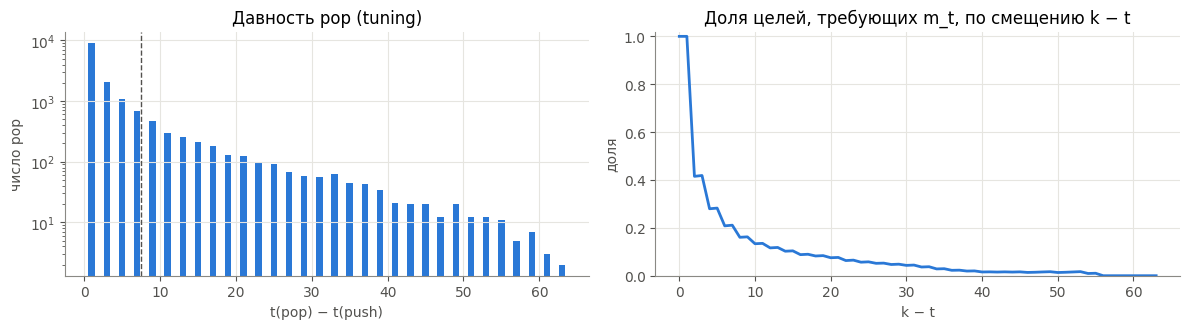

In [2]:
validation = S.sample_stack(CFG, CFG.validation_examples, S.derive_seed(501, 0))
tuning = S.sample_stack(CFG, CFG.tuning_examples, S.derive_seed(502, 0))
display(pd.DataFrame([dict(split=n, **S.data_audit(b, CFG)) for n, b in (("validation", validation), ("tuning", tuning))]))

sub = S.slice_batch(tuning, 0, 64)
w = S.windows(sub)
v = w["valid"]
pairs = pd.DataFrame(dict(offset=(w["target_t"] - w["anchor"][:, None])[v].numpy(),
                          delay=w["delay"][v].numpy(), memory_dependent=w["prefix"][v].numpy()))
print(f"(anchor, target) пар: {len(pairs)}; требуют памяти m_t (push ≤ t): {pairs.memory_dependent.mean():.1%}; "
      f"требуют m_t и delay ≥ {CFG.long_delay}: {((pairs.delay >= CFG.long_delay) & pairs.memory_dependent).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
d = tuning["delay"][tuning["target_mask"]].numpy()
axes[0].hist(d, bins=np.arange(1, 65) - .5, color=SERIES[0], rwidth=.85)
axes[0].axvline(CFG.long_delay - .5, color="#52514e", ls="--", lw=1)
axes[0].set(title="Давность pop (tuning)", xlabel="t(pop) − t(push)", ylabel="число pop", yscale="log")
share = pairs.groupby("offset").memory_dependent.mean()
axes[1].plot(share.index, share.values, color=SERIES[0])
axes[1].set(title="Доля целей, требующих m_t, по смещению k − t", xlabel="k − t", ylabel="доля", ylim=(0, 1.02))
plt.tight_layout(); plt.show()

В Stack давность всегда нечётная (между push и pop элемента лежат только сбалансированные пары операций), поэтому группа «delay ≥ 8» совпадает с «delay ≥ 9». Смещение 0 (y_t по m_t) всегда требует памяти — это и есть цель RNN readout. Чем дальше цель от anchor, тем чаще её элемент положен уже после t и виден декодеру во входах x_fut.

## 4. Технические проверки (CPU, ~1 мин)

Скрипт `checks/test_smt_memup_stack.py` — 16 проверок на маленьких моделях: в том числе отсутствие metadata в отборе, причинность контекстного detector, определение oracle, resume посреди SMT и DMT; оптимизационные шаги делают только проверки resume на крошечной конфигурации, во временном каталоге.

In [3]:
r = subprocess.run([sys.executable, str(ROOT / "checks/test_smt_memup_stack.py")], capture_output=True, text=True, cwd=ROOT)
print("\n".join(l for l in r.stdout.splitlines() if l.startswith(("OK", "\n")) or "passed" in l))
assert r.returncode == 0, r.stderr[-3000:]

OK  Stack: author generator, replay annotation, paper example, seed reproducibility
OK  Windows: shifts equal the author get_smt_batch at anchor t=Tc-1; prefix/future partition
OK  Teacher: left padding is exactly masked; m_t independent of future inputs (no leakage)
OK  Decoder: output j sees only memory + x_fut[:j]; teacher_readout == decode[:, 0]; RNN readout == teacher head after copy
OK  Loss normalisation: alpha=0 identical for all variants; uniform == (1+alpha) L_dec; E[random-K] == L_dec
OK  Top-K: equals MemUP TopKSelector inside the pool; never duplicates; pool<K -> whole pool
OK  Gradients: SMT reaches encoder+updater, not detectors; DMT readout CE never reaches updater; teacher frozen
OK  Context detector: output j depends only on x_fut[:j] (same information as decoder, no memory)
OK  Training: same seed -> same initial weights for every variant; rerun after a lost DMT stage is identical
OK  Mid-stage resume: crash after step 3 of 6 reproduces the uninterrupted SMT weights


## 5. Фаза 0: detector и аудит отбора (без обучения SMT)

Два score, оба замороженные и без metadata:

* **`surprise_k` (основной вариант):** $s_k=-\log q(y_k\mid x_{k-r+1..k})$. Согласован принцип «неожиданность по локальному контексту»; **окно r = 8 выбрали мы**. Как в MemUP, score не зависит от anchor.
* **`surprise_ctx_k` (вторичная диагностика):** $s_k(t)=-\log q(y_k\mid x_{t+1..k})$ — ровно те входы, которые видит decoder SMT для anchor t, но **без памяти**. Высокий score означает: цель нельзя вывести из того, что decoder и так видит. Это отдельный GRU, обученный с нуля на [BOS, x_{t+1..t+j}] → y_{t+j}; он не видит памяти, префикса x_{≤t} и ответов. Это не декодер teacher с удалённой памятью.

**Oracle `oracle_prefix_k` (вторичная диагностика)** выбирает min(K, P_t) случайных целей с push ≤ t по metadata генератора. Давность не используется, так что короткие зависимости из префикса тоже входят. Нормировка: среднее внутри anchor, anchors с весом P_t, общий вес alpha. Это не алгоритм MemUP; oracle помогает интерпретации, но не даёт однозначного объяснения любого исхода.

Metadata читается только после выбора. Повторный запуск ячейки загружает сохранённые detector.

In [4]:
EX = S.Experiment(CFG, root=ROOT, device=DEVICE)
print("run directory:", EX.dir)
audit = EX.audit()
display(pd.DataFrame(audit["detector_quality"]).T)
sel = audit["selection"]
display(sel)

run directory: /mem/work/runs/stack02_4c69a2819ab8


,ce,acc_inside_window,acc_outside_window,auc_outside_window,n,mean_ce_future_source,mean_ce_prefix_source,auc_prefix_source
window,0.218116,1.0,0.251378,1.0,15377.0,NaN,NaN,NaN
context,0.279079,NaN,NaN,NaN,521856.0,0.054685,1.412223,0.986716


,rule,anchors,pairs,memory_dependent,long_memory_dependent,future_source,mean_delay,mean_offset,anchors_with_pool_le_K
0,random_k,all anchors,123169,0.223270,0.111278,0.776730,5.523476,16.890987,0.122681
1,random_k,pool > K,113108,0.195724,0.109426,0.804276,5.577501,18.148159,0.122681
2,surprise_k,all anchors,123169,0.412563,0.322971,0.587437,14.302617,18.013908,0.122681
3,surprise_k,pool > K,113108,0.401855,0.339949,0.598145,15.137550,19.370964,0.122681
4,surprise_ctx_k,all anchors,123169,0.602376,0.317020,0.397624,12.871689,13.610284,0.122681
5,surprise_ctx_k,pool > K,113108,0.608551,0.333469,0.391449,13.579340,14.575636,0.122681
6,oracle_prefix_k,all anchors,75590,1.000000,0.527411,0.000000,14.434634,7.211351,0.122681
7,oracle_prefix_k,pool > K,70228,1.000000,0.548755,0.000000,14.922026,7.670117,0.122681
8,random_k (exact expectation),all anchors,123169,0.223839,0.112029,0.776161,NaN,NaN,0.122681
9,random_k (exact expectation),pool > K,113108,0.196343,0.110244,0.803657,NaN,NaN,0.122681


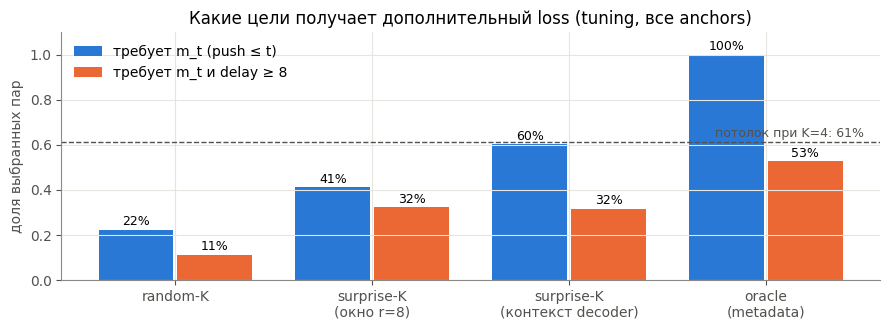

* Окно r=8 отделяет цели «вне окна» идеально (AUC 1.000), но **59%** выбранных пар имеют источник после anchor (у random-K 78%).
* Доля пар, требующих m_t и delay ≥ 8: random 11.2%, окно 32.3%, контекст decoder 31.7%. Обогащение есть у обоих score.
* По всем memory-dependent целям контекстный score (60%) почти достигает потолка (61%); окно — 41%.
* У 12% anchors пул ≤ K: там любой метод выбирает весь пул.

Это свойства отбора, а не эффект на обучение. Лучшее обогащение не гарантирует лучшую память.

In [5]:
s = sel[sel.anchors == "all anchors"].set_index("rule")
rules = ["random_k (exact expectation)", "surprise_k", "surprise_ctx_k", "oracle_prefix_k"]
labels = ["random-K", "surprise-K\n(окно r=8)", "surprise-K\n(контекст decoder)", "oracle\n(metadata)"]
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(rules))
ax.bar(x - .2, s.loc[rules, "memory_dependent"], .38, color=SERIES[0], label="требует m_t (push ≤ t)")
ax.bar(x + .2, s.loc[rules, "long_memory_dependent"], .38, color=SERIES[1], label=f"требует m_t и delay ≥ {CFG.long_delay}")
ceiling = s.loc["oracle_prefix_k", "pairs"] / s.loc["random_k", "pairs"]
ax.axhline(ceiling, color="#52514e", ls="--", lw=1)
ax.text(len(rules) - .5, ceiling + .02, f"потолок при K={CFG.K}: {ceiling:.0%}", ha="right", color="#52514e", fontsize=9)
for i, r_ in enumerate(rules):
    ax.text(i - .2, s.loc[r_, "memory_dependent"] + .02, f"{s.loc[r_, 'memory_dependent']:.0%}", ha="center", fontsize=9)
    ax.text(i + .2, s.loc[r_, "long_memory_dependent"] + .02, f"{s.loc[r_, 'long_memory_dependent']:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, labels); ax.set_ylim(0, 1.1); ax.set_ylabel("доля выбранных пар")
ax.set_title("Какие цели получает дополнительный loss (tuning, все anchors)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

r0, rw, rc = (s.loc[k] for k in ("random_k (exact expectation)", "surprise_k", "surprise_ctx_k"))
display(Markdown(
    f"* Окно r=8 отделяет цели «вне окна» идеально (AUC {audit['detector_quality']['window']['auc_outside_window']:.3f}), "
    f"но **{rw.future_source:.0%}** выбранных пар имеют источник после anchor (у random-K {r0.future_source:.0%}).\n"
    f"* Доля пар, требующих m_t и delay ≥ {CFG.long_delay}: random {r0.long_memory_dependent:.1%}, окно {rw.long_memory_dependent:.1%}, "
    f"контекст decoder {rc.long_memory_dependent:.1%}. Обогащение есть у обоих score.\n"
    f"* По всем memory-dependent целям контекстный score ({rc.memory_dependent:.0%}) почти достигает потолка ({ceiling:.0%}); окно — {rw.memory_dependent:.0%}.\n"
    f"* У {s.anchors_with_pool_le_K.iloc[0]:.0%} anchors пул ≤ K: там любой метод выбирает весь пул.\n\n"
    "Это свойства отбора, а не эффект на обучение. Лучшее обогащение не гарантирует лучшую память."))

## 6. Протокол и стоимость

* Внутри seed у всех вариантов одинаковые начальные веса (проверяется хэшем), train-батчи, anchors, случайные потоки и число шагов.
* Checkpoint выбирается по **validation** (SMT: teacher CE на pop с delay ≥ 8; DMT: RNN CE на тех же pop). Последние веса тоже сохраняются и оцениваются на test как проверка устойчивости выбора.
* Alpha выбирается для **каждого** небазового варианта по одной сетке {0,1; 0,3; 1,0} и одному бюджету, по **отдельному tuning-набору** (CE RNN после DMT на дальних pop), на отдельном tuning-seed 107. Финальные seeds 7/17/27 в подборе не участвуют.
* Test (2048 последовательностей) генерируется только в `final_report(confirm_test=True)`, после фиксации alpha и всех fits.
* Основная метрика: CE RNN после DMT на pop с delay ≥ 8; обязательная сопутствующая — accuracy. Отдельно teacher, RNN до DMT, «shared» (та же голова teacher на состоянии RNN), MSE памяти (вспомогательная).
* Статистика: парные разности на одних test-последовательностях: размер эффекта (среднее по seeds), значение каждого seed, 95% интервал по последовательностям (pop внутри последовательности зависимы). Интервал «seeds × sequences» при 3 seeds ненадёжен. «Лучше у всех seeds» — критерий устойчивости, а не замена размеру эффекта.
* Бюджет фиксированный и одинаковый; baseline на нём уже содержательно решает задачу (gate). Отсутствие эффекта на этом бюджете — не общее опровержение гипотезы.

Ниже — замер стоимости на этом GPU, по 10 шагов на одноразовых моделях (≈ 1 мин).

In [6]:
RUN_BENCHMARK = False
if RUN_BENCHMARK:
    bench = S.benchmark(CFG, DEVICE)
else:   # измерено на RTX 5090 при параллельной нагрузке сервера, 13.10.2026
    bench = dict(smt_s_per_step=0.100, smt_peak_mib=7733, dmt_s_per_step=0.524, dmt_peak_mib=3212, eval_s=1.08)
display(pd.DataFrame([bench]))
display(S.plan(CFG, bench))
display(pd.DataFrame([config := S.config_json(CFG)]).T.rename(columns={0: "value"}))

,smt_s_per_step,smt_peak_mib,dmt_s_per_step,dmt_peak_mib,eval_s
0,0.1,7733,0.524,3212,1.08


,phase,fits,smt_steps,dmt_steps,hours_est
0,baseline_gate,1,3000,1500,0.307067
1,alpha_tuning,9,27000,13500,2.763600
2,final,12,36000,18000,3.684800


,value
seq_len,64
n_elements,4
max_stack_size,8
long_delay,8
d_model,64
mem_tokens,8
encoder_depth,3
decoder_depth,2
rnn_depth,2
n_heads,4


## 7. Фаза 1: рабочий baseline (один fit, ≈ 20 мин)

Сначала только baseline на tuning-seed. Gate на tuning-наборе: teacher (после SMT) на дальних pop ≥ chance + 10 п.п., RNN после DMT ≥ chance + 5 п.п. Пороги — наши инженерные ограничения бюджета, не согласованные научником и не доказательство освоения задачи. Если gate не пройден, сравнение вариантов не запускается: разбираем кривые на validation и меняем конфиг **отдельным** запуском (новый каталог), test не создаётся.

Для фоновых запусков удобнее CLI (переживает закрытие браузера, resume автоматический):

```bash
cd /mem/work && nohup nice -n 10 /mem/envs/smt-memup/bin/python smt_memup_stack.py --phase baseline --threads 4 --gpu-memory-fraction 0.35 > runs/baseline.log 2>&1 &
```

In [7]:
RUN_BASELINE = False
if RUN_BASELINE:
    base = EX.baseline()
    display(base["gate"])
    display(base["summary"].query("group != 'all'"))
else:
    print("Фаза 1 выключена. Поставьте RUN_BASELINE=True или запустите CLI.")

Фаза 1 выключена. Поставьте RUN_BASELINE=True или запустите CLI.


### 7.1. Кривые обучения и проверка H2 (читаются из сохранённых файлов baseline)

*Слева:* validation accuracy на дальних pop по шагам SMT и DMT. *Справа:* probe H2 на tuning: RNN стартует из памяти teacher в момент s и делает L обновлений на настоящих входах; ответ y_{s+L} читается той же замороженной головой teacher. Если teacher держит уровень, а RNN падает с ростом L — информация теряется в updater, а не в encoder.

In [8]:
def show_baseline(directory):
    base_dir = directory / "tuning" / "baseline"
    if not (directory / "baseline_gate.json").exists():
        print("Нет результатов baseline:", directory); return
    gate = json.loads((directory / "baseline_gate.json").read_text())
    display(pd.DataFrame([gate]))
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    offset = 0
    for stage in ("smt", "dmt"):
        h = pd.read_csv(base_dir / f"{stage}_history.csv").dropna(subset=["val_teacher_long_acc"])
        axes[0].plot(h.step + offset, h.val_teacher_long_acc, color=SERIES[0], label="teacher" if stage == "smt" else None)
        axes[0].plot(h.step + offset, h.val_rnn_long_acc, color=SERIES[1], label="RNN" if stage == "smt" else None)
        if stage == "smt":
            offset = int(h.step.max()); axes[0].axvline(offset, color="#8a8984", lw=1, ls=":")
    axes[0].axhline(1 / CFG.n_elements, color="#8a8984", lw=1, ls="--")
    axes[0].set(title=f"validation, pop с delay ≥ {CFG.long_delay} (SMT | DMT)", xlabel="шаг", ylabel="accuracy", ylim=(0, 1))
    axes[0].legend(frameon=False)
    pr = pd.read_csv(directory / "baseline_retention_probe.csv")
    pr = pr[pr.delay >= CFG.long_delay].groupby(["model", "horizon"]).correct.mean().unstack(0)
    axes[1].plot(pr.index, pr["teacher"], marker="o", color=SERIES[0], label="teacher в момент s+L")
    axes[1].plot(pr.index, pr["rnn_from_teacher"], marker="o", color=SERIES[1], label="RNN: старт из teacher(s), L шагов")
    axes[1].axhline(1 / CFG.n_elements, color="#8a8984", lw=1, ls="--")
    axes[1].set(title=f"H2: дальние pop (delay ≥ {CFG.long_delay}), общая голова teacher", xlabel="L, число обновлений RNN",
                ylabel="accuracy", ylim=(0, 1), xscale="symlog")
    axes[1].legend(frameon=False); plt.tight_layout(); plt.show()
    ev = pd.read_csv(directory / "baseline_tuning_events.csv")
    ev["delay_bin"] = pd.cut(ev.delay, [0, 2, 4, 8, 16, 64], labels=["1–2", "3–4", "5–8", "9–16", "17+"], right=True)
    display(ev.groupby(["stage", "model", "delay_bin"], observed=True).agg(
        pops=("correct", "size"), acc=("correct", "mean"), ce=("ce", "mean"),
        shared_acc=("shared_correct", "mean"), memory_mse=("memory_mse", "mean")).unstack("delay_bin").round(3))

show_baseline(EX.dir)

Нет результатов baseline: /mem/work/runs/stack02_4c69a2819ab8


## 8. Фаза 2: подбор alpha (≈ 2,8 ч, только после gate)

Основное сравнение — baseline, uniform, random-K, surprise-K. Вторичные диагностические `surprise_ctx_k` и `oracle_prefix_k` включены до запуска tuning (решение 13.10). Все шесть входят в отчёт по test; после просмотра test варианты не добавляются и не исключаются.

### 8.0. Предрегистрация сравнения H1 — версия 2 (13.10.2026)

Версия 2 уточняет только текст. Она написана во время первого tuning-fit (uniform, alpha=0.1); результаты
tuning для изменения правил не использовались. Код, конфиг, варианты и alpha-сетка не менялись
(`smt_memup_stack.py` sha256 f0552c46…). Версия 1 — `preregistration_v1.md`.

#### Что согласовано с научником и что выбрали мы
Согласовано: к исходному SMT loss с весом добавить MemUP-inspired слагаемое, учитывающее неожиданность
будущих событий; начать без шума (Stack или MQAR); MNIST — следующий этап; отдельно проверить, сохраняется
ли информация энкодера при последовательных обновлениях RNN. Обсуждалась проблема целей с источником после
anchor: они неожиданны для локального предиктора, но доступны декодеру без m_t.

**Наши настройки, научником не фиксировались:** окно r=8, K=4, размеры моделей, число шагов, seeds,
alpha-сетка, пороги gate, первичная метрика.

Запуск `runs/stack02_4c69a2819ab8`: Stack T=64, глубина 8, 4 значения; SMT 3000 шагов, DMT 1500, batch 32,
все anchors; K=4; alpha ∈ {0.1, 0.3, 1.0}.

#### Бюджет
Бюджет фиксированный и одинаковый для всех вариантов, при этом baseline уже содержательно решает задачу:
gate пройден на tuning-наборе, teacher 38%, RNN после DMT 41% на pop с delay ≥ 8 при случайном уровне 25%;
pop с delay ≤ 8 решены почти полностью. «Ограниченный бюджет» не означает, что baseline должен оставаться
недообученным. **Отсутствие эффекта на этом бюджете не является общим опровержением гипотезы.**

#### Loss (как в коде)
L = L_dec + 0,1·L_dyn + 0,001·L_unif + alpha·L_sel. Первые три слагаемых — авторские, с авторскими коэффициентами:
* L_dec — среднее CE по всем допустимым парам (anchor t, цель k ≥ t), все anchors, Tc = Tf = T;
* L_dyn — MSE f(m_{t−1}, x_t) → m_t, плюс наш начальный переход f(0, x_0) → m_0; градиент идёт в обе стороны,
  как `detach_rnn=False` у автора;
* L_unif — uniformity по memory-токенам.

L_sel = Σ_t N_t · mean_{k∈S_t} CE_{t,k} / Σ_t N_t, где N_t — размер пула anchor t, S_t — выбранные цели.
Если пул — все допустимые цели, то E[L_sel] для random-K равно L_dec, а uniform даёт ровно (1+alpha)·L_dec.

Градиент L_sel идёт в decoder и через m_t в encoder teacher; в updater RNN он не попадает: updater учится
только через L_dyn. Score вычисляется под `no_grad` замороженным detector, top-K недифференцируем.
Metadata генератора (источник, давность, глубина) не используется ни в одном варианте, кроме oracle;
это проверено тестом: если перемешать metadata, loss всех не-oracle вариантов не меняется.

#### Варианты (список фиксирован, все шесть входят в отчёт по test)
| вариант | роль | отбор |
|---|---|---|
| baseline | контекст | — |
| uniform | основной контроль | alpha·L_dec |
| random_k | основной контроль | K случайных из всех допустимых целей k ≥ t |
| surprise_k | **основной проверяемый вариант** | top-K по −log q(y_k \| x_{k−7..k}); score не зависит от anchor, как в MemUP |
| surprise_ctx_k | вторичная диагностика | top-K по −log q(y_k \| x_{t+1..k}) |
| oracle_prefix_k | вторичная диагностика, ORACLE | K случайных среди целей с push ≤ t |

**surprise_ctx_k.** Отдельный GRU обучен с нуля (2000 шагов, свежие train-последовательности, best по
validation CE) предсказывать y_{t+j} по [BOS, x_{t+1}, …, x_{t+j}] для всех anchors. Это ровно те входы,
которые видит decoder SMT для этой цели. Он не видит ни m_t, ни префикс x_{≤t}, ни какие-либо ответы.
Тест: score пары (t, k) не меняется при изменении x_{≤t}, x_{>k} и всех меток, кроме y_k. Это **не**
декодер teacher с удалённой памятью. Он тоже не видит памяти, но его высокая неожиданность не равна
доказательству, что ответ содержится именно в m_t.

**oracle_prefix_k.** Критерий: элемент положен не позже anchor (push ≤ t). Давность **не** используется,
поэтому сюда входят и короткие зависимости из префикса. Внутри каждого anchor выбираются min(K, P_t)
случайных целей, где P_t — число таких целей; это обычно меньше K, а anchors с P_t = 0 дополнительного
слагаемого не получают. Нормировка: среднее внутри anchor, anchors с весом P_t, общий вес alpha·coef_dec —
как у остальных. E[L_sel] = среднее CE по memory-dependent парам. Отличия от контролей: другое число
выбранных пар и другой вес anchors. Oracle помогает интерпретации, но не даёт однозначного объяснения
любого исхода.

#### Протокол
* Внутри seed у всех вариантов совпадают начальные веса (проверка хэшем), поток train-данных, anchors
  (все), случайные выборы (seed = f(seed, step)) и бюджет. Resume восстанавливает optimizer, scheduler и
  историю; на CPU прерванный прогон совпадает с непрерывным бит в бит (тесты для SMT и DMT). На GPU
  побитовое совпадение не гарантируется из-за недетерминированных ядер, последовательность случайных
  выборов от этого не зависит.
* Alpha: одинаковая сетка и одинаковый бюджет для каждого небазового варианта; tuning-seed 107; критерий —
  CE RNN после DMT на pop с delay ≥ 8 на отдельном tuning-наборе.
* Checkpoint для всех: SMT — лучшая teacher CE, DMT — лучшая RNN CE на тех же pop на validation.
  Последние веса оцениваются как проверка устойчивости.
* Test создаётся один раз после всех final fits; на нём ничего не выбирается.
  Команда (все шесть вариантов):
  `python smt_memup_stack.py --phase report --confirm-test --variants baseline,uniform,random_k,surprise_k,surprise_ctx_k,oracle_prefix_k`

#### Метрики
**Первичная:** CE RNN после DMT на test-pop с delay ≥ 8 (в Stack давность нечётная, это delay ≥ 9).

**Обязательно показываются:**
* accuracy той же группы;
* общие CE и accuracy, а также группы delay < 8 и ≥ 16;
* teacher; RNN до и после DMT;
* RNN через голову teacher;
* результаты каждого seed;
* checkpoint `last`.

MSE памяти — вспомогательная метрика: её снижение само по себе не подтверждает сохранение информации.

#### Сравнения (разность variant − reference на одних test-последовательностях)
* основные: surprise_k − random_k, surprise_k − uniform;
* контекст: uniform, random_k и surprise_k минус baseline;
* вторичные: surprise_ctx_k − {random_k, uniform, surprise_k}; oracle − {random_k, uniform, surprise_k}.

Для каждой разности: размер эффекта (среднее по seeds), значение каждого seed, 95% интервал при
ресэмплинге последовательностей (pop внутри последовательности зависимы) и интервал «seeds × последовательности».
Последний при трёх seeds ненадёжен.

#### Правило вывода по основным сравнениям
H1 поддержана при этом бюджете, если для **обоих** основных сравнений выполнено всё:
1. средняя разность CE < 0;
2. разность CE < 0 у каждого из трёх seeds — критерий устойчивости, не замена размеру эффекта;
3. 95% интервал по последовательностям для средней разности не содержит 0;
4. средняя разность accuracy той же группы не отрицательна.

Даже тогда свидетельство предварительное: тот же протокол повторяется на двух дополнительных seeds.
Если правило не выполнено, H1 при этом бюджете не поддержана; приводятся размеры эффектов и интервалы.

Вторичные ветки интерпретируются осторожно, тем же правилом знаков и интервалов:
* oracle не лучше контролей — при этом бюджете усиление memory-dependent целей само по себе не дало
  выигрыша; возможны и другие объяснения, например нормировка или число выбранных пар;
* oracle лучше, surprise_k нет — узким местом вероятно является score; surprise_ctx_k показывает, помогает ли учёт anchor;
* teacher улучшается, RNN нет — проблема переноса в updater (H2), а не довод против отбора.

#### Ёмкость памяти
Память 8×64 больше числа элементов стека, но это не доказывает, что обученная модель эффективно
использует эту ёмкость. Размер памяти в эксперименте зафиксирован; гипотеза о поведении при разных
ограничениях ёмкости здесь не проверяется.

#### Чего не делаем
Не меняем конфиг, alpha, K, правило выбора checkpoint, список вариантов или правило вывода после создания
test; не исключаем варианты из отчёта; не выдаём surprise_ctx_k и oracle за согласованный метод.


In [9]:
VARIANTS = S.VARIANTS_AGREED + ("surprise_ctx_k", "oracle_prefix_k")   # решение 13.10, см. 8.0
RUN_TUNE = False
if RUN_TUNE:
    tuned = EX.tune(VARIANTS)
    display(tuned["table"]); print("locked:", tuned["alphas"])
elif (EX.dir / "alpha_tuning.csv").exists():
    display(pd.read_csv(EX.dir / "alpha_tuning.csv")); print(json.loads((EX.dir / "locked_alphas.json").read_text()))
else:
    print("Фаза 2 выключена.")

Фаза 2 выключена.


## 9. Фазы 3–4: финальные fits и единственная оценка на test

`final_fits` обучает 3 seeds × варианты (≈ 3,7 ч для четырёх). `final_report(confirm_test=True)` создаёт test и считает парные разности. После этого протокол не меняется.

In [10]:
RUN_FINAL_FITS = False
RUN_TEST_REPORT = False                # отдельно и только один раз, все шесть вариантов
if RUN_FINAL_FITS:
    EX.final_fits(VARIANTS)
if RUN_TEST_REPORT:
    report = EX.final_report(VARIANTS, confirm_test=True)

# Все заранее заявленные сравнения (раздел 8.0); считаются из сохранённых test-событий.
PREREG_COMPARISONS = (
    [("random_k", "surprise_k"), ("uniform", "surprise_k")]                                  # основные
    + [("baseline", v) for v in ("uniform", "random_k", "surprise_k")]                       # контекст
    + [(r, "surprise_ctx_k") for r in ("random_k", "uniform", "surprise_k")]                 # вторичные
    + [(r, "oracle_prefix_k") for r in ("random_k", "uniform", "surprise_k")])
if (EX.dir / "test_events.csv").exists():
    events = pd.read_csv(EX.dir / "test_events.csv")
    assert set(events.variant) == set(VARIANTS), "в отчёте должны быть все заявленные варианты"
    best = events[events.checkpoint == "best"]
    iv, ps = S.paired_deltas(best, CFG, PREREG_COMPARISONS)
    iv.to_csv(EX.dir / "test_intervals_prereg.csv", index=False); ps.to_csv(EX.dir / "test_per_seed_prereg.csv", index=False)
    primary = (ps.model == "rnn") & (ps.stage == "dmt") & ps.metric.isin(["ce", "correct"])
    display(Markdown("**Разности variant − reference по каждому seed (RNN после DMT, pop с delay ≥ 8).** CE: меньше — лучше."))
    display(ps[primary].pivot_table(index=["reference", "variant", "metric"], columns="seed", values="delta").round(4))
    display(Markdown("**Размер эффекта и интервалы (все модели и стадии).**"))
    display(iv.round(4))
    main = iv[(iv.model == "rnn") & (iv.stage == "dmt") & (iv.variant == "surprise_k") & iv.reference.isin(["random_k", "uniform"])]
    ce, acc = main[main.metric == "ce"].set_index("reference"), main[main.metric == "correct"].set_index("reference")
    rule = {ref: bool(ce.loc[ref, "delta_mean"] < 0 and ce.loc[ref, "seeds_same_sign"] == ce.loc[ref, "seeds"]
                      and ce.loc[ref, "ci_sequences_high"] < 0 and acc.loc[ref, "delta_mean"] >= 0)
            for ref in ("random_k", "uniform")}
    display(Markdown(f"**Правило 8.0 для основных сравнений:** {rule} → H1 при этом бюджете "
                     + ("поддержана (предварительно; повторить на 2 доп. seeds)." if all(rule.values()) else "не поддержана.")))
    sm = pd.read_csv(EX.dir / "test_summary.csv")
    display(sm.pivot_table(index=["group", "stage", "model", "variant"], columns=["checkpoint", "seed"],
                           values=["accuracy", "ce"]).round(3))
else:
    print("Test ещё не создан.")

Test ещё не создан.


## 10. Что исправлено относительно версии 01

| Где в 01 | Проблема | Последствие | В 02 |
|---|---|---|---|
| ячейка 95 | `RUN_STRONG_EXPERIMENT=True`, `STRONG_PHASE="full"` вопреки тексту | Run All запускает весь протокол (детектор уже начал обучаться в сохранённом output) | все фазы выключены; test только в отдельном вызове с `confirm_test=True` |
| ячейка 93, `STRONG_CODE_SHA` | константа, не совпадает с хэшем кода ячейки | после правки кода resume молча подхватывает старые checkpoints | хэш считается из файла кода |
| `strong_smt_loss`, `strong_row_loss` | decoder CE усредняется сначала по anchor, потом между anchors | меняет исходный $L_{SMT}$ (согласовано: сохранить); поздние anchors с 1–2 целями весят как ранние | авторское среднее по всем парам; дополнительная CE с весом N_t, E[random-K] = L_dec |
| `strong_smt_loss` | 8 anchors × batch 4 = 32 окна за шаг | в 64 раза меньше окон, чем протокол статьи (batch 32 × все T) | все anchors, batch 32 (Monte Carlo-подвыборка доступна параметром) |
| `strong_fit`, eval | `eval_batch_size=2`, DMT batch 4 | для 4 ГБ GPU; на 5090 оценка и DMT упираются в число последовательных вызовов | eval 128, DMT batch 32; стоимость измерена |
| `strong_bootstrap` | сравнивает только stage `dmt`; ресэмплинг из 3 seeds выдаётся за интервал | нет сравнения RNN до DMT; CI по 3 seeds вводит в заблуждение | stage smt и dmt, own и shared head, отдельные таблицы по seeds и знаки |
| отбор (01 §8, 17) | score не зависит от anchor, пул не различает источник до/после t | в 01: 64% выбранных пар с источником после anchor; в 02 на T=64: 59% | аудит доли memory-dependent целей; опциональный контекстный score и oracle-контроль |
| detector gate | проверяет только локальность (acc внутри окна, AUC вне окна) | проходит идеально, ничего не говоря о пользе для m_t | gate сохранён как sanity; основная диагностика — аудит отбора |
| `peak_allocated_mib` | `max_memory_allocated` без сброса | пик за весь процесс, не за этап | сброс в начале этапа |
| 01 §9 (архив) | alpha подбирался только для surprise-K и переносился на контроли | несимметричный подбор | одинаковая сетка и бюджет для каждого метода |

Не подтвердились как ошибки: индексация окон (совпадает с авторским `get_smt_batch`), маскирование left padding в encoder (совпадает с прямым кодированием префикса до 2e-5), causal decoder, начальный переход `encode(x[:, :1])` в разделе 17 (эквивалентен padded-версии), отсутствие task-градиента в updater при DMT.

## 11. Архив версии 01 (не результаты этого кода)

Ниже — числа из сохранённых outputs загруженного ноутбука 01, один training seed, другие размеры (T=24, глубина 3, d=32, 800 SMT + 300 DMT шагов, batch 8). Код 02 их не воспроизводил.

| Stack, RNN после DMT | Accuracy, все | Accuracy, delay ≥ 8 | CE, delay ≥ 8 |
|---|---:|---:|---:|
| baseline | 86,10% | 39,83% | 1,3418 |
| uniform | 86,47% | 43,18% | 1,2674 |
| random-K | 86,40% | 41,78% | 1,2832 |
| surprise-K | 86,48% | 35,65% | 1,3366 |

* Дальних pop около 6%; teacher на них тоже слабый, поэтому пилот не различает «encoder не выучил» и «updater потерял».
* alpha подобран только для surprise-K короткими запусками.
* MQAR (Zoology, vocab 128, 8 пар, 3 600 SMT-последовательностей): teacher выбирает верное значение из 8 записанных в 12,7% случаев при случайном 12,5% — связывание ключ–значение не выучено; для Zoology-моделей обычно нужны на порядки больше примеров.
* MNIST: argmax всегда 0 (accuracy = доля чёрных пикселей), 150 SMT-шагов на фрагментах длины 32; выигрыш CE 0,014 не говорит о дальних зависимостях.